 0) IMPORT & SETTINGS

In [ ]:
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef
)

import joblib
import sklearn

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
DATA_PATH = "/content/creditcard.csv"  # pastikan file ada di panel Files (kiri)
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH}\n"
        "Pastikan creditcard.csv sudah ada di /content (panel Files kiri)."
    )

df = pd.read_csv(DATA_PATH)
print("File terbaca:", DATA_PATH)
print("Shape:", df.shape)

required_cols = {"Class", "Time", "Amount"}
if not required_cols.issubset(df.columns):
    raise ValueError(
        f"Kolom wajib tidak lengkap. Harus ada: {required_cols}. "
        f"Kolom sekarang: {df.columns.tolist()}"
    )

df.head()

File terbaca: /content/creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


2) DATA PREPARATION / CHECK


In [ ]:
print("\nINFO DATASET")
print(df.info())

missing = df.isna().sum().sort_values(ascending=False)
print("\nMissing values (top 10):")
print(missing.head(10))

dup_count = df.duplicated().sum()
print("\nJumlah duplikasi:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplikasi dihapus. Shape baru:", df.shape)

print("\nDistribusi label Class:")
print(df["Class"].value_counts())
print("Fraud rate (%):", df["Class"].mean() * 100)



INFO DATASET
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 

3) EDA VISUALIZATION

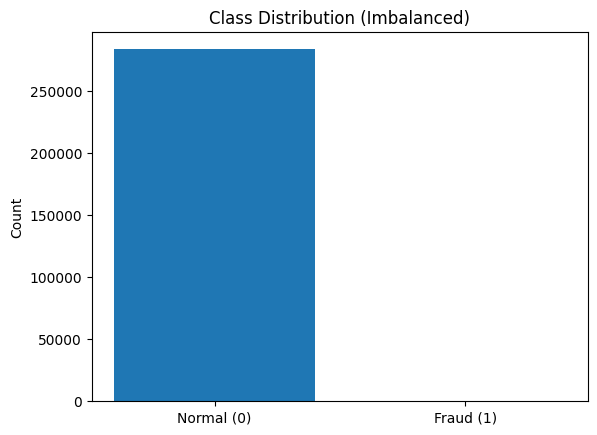

In [ ]:
# A) Distribusi kelas (imbalance)
counts = df["Class"].value_counts().sort_index()
plt.figure()
plt.bar(["Normal (0)", "Fraud (1)"], counts.values)
plt.title("Class Distribution (Imbalanced)")
plt.ylabel("Count")
plt.show()

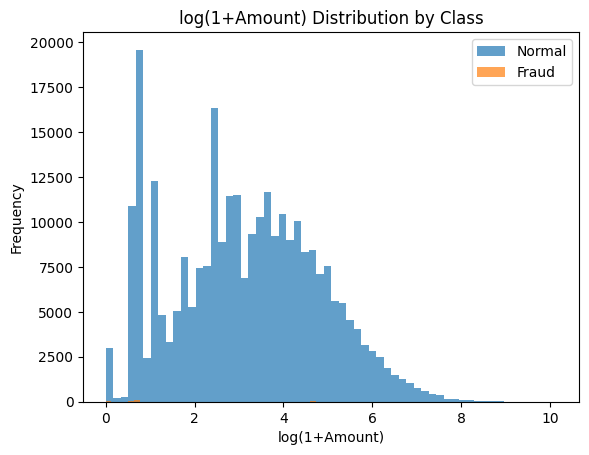

In [ ]:
# B) Distribusi Amount (log) per kelas
plt.figure()
plt.hist(np.log1p(df[df["Class"] == 0]["Amount"]), bins=60, alpha=0.7, label="Normal")
plt.hist(np.log1p(df[df["Class"] == 1]["Amount"]), bins=60, alpha=0.7, label="Fraud")
plt.title("log(1+Amount) Distribution by Class")
plt.xlabel("log(1+Amount)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

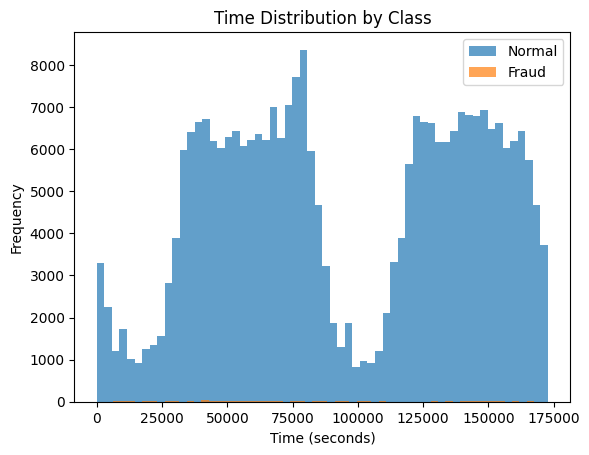

In [ ]:
# C) Distribusi Time per kelas
plt.figure()
plt.hist(df[df["Class"] == 0]["Time"], bins=60, alpha=0.7, label="Normal")
plt.hist(df[df["Class"] == 1]["Time"], bins=60, alpha=0.7, label="Fraud")
plt.title("Time Distribution by Class")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

4) SPLIT DATA (STRATIFIED) Train/Val/Test

In [ ]:
X = df.drop(columns=["Class"])
y = df["Class"]

# 80% train_val, 20% test
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# dari train_val, 20% untuk val => train 64%, val 16%
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.20,
    stratify=y_trainval,
    random_state=RANDOM_STATE
)

print("\nSPLIT SHAPE")
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("Fraud rate Train/Val/Test (%):",
      y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100)



SPLIT SHAPE
Train: (181584, 30) Val: (45396, 30) Test: (56746, 30)
Fraud rate Train/Val/Test (%): 0.16631421270596528 0.1674156313331571 0.16741268107003138


# 5) PREPROCESSING (Pipeline, anti leakage)
# - Scale Time & Amount
# - Pass-through V1..V28

In [ ]:
scale_cols = ["Time", "Amount"]
pass_cols = [c for c in X.columns if c not in scale_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("scale", StandardScaler(), scale_cols),
        ("pass", "passthrough", pass_cols)
    ]
)


 6) BASELINE MODEL (optional quick check)

In [ ]:
rf_baseline = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

baseline_model = Pipeline(steps=[
    ("prep", preprocess),
    ("rf", rf_baseline)
])

baseline_model.fit(X_train, y_train)
val_proba_base = baseline_model.predict_proba(X_val)[:, 1]

print("\nBASELINE (VAL) ROC-AUC:", roc_auc_score(y_val, val_proba_base))
print("BASELINE (VAL) PR-AUC(AP):", average_precision_score(y_val, val_proba_base))


BASELINE (VAL) ROC-AUC: 0.9514801179913597
BASELINE (VAL) PR-AUC(AP): 0.8736104403264712


 7) HYPERPARAMETER OPTIMIZATION (RandomizedSearchCV)

In [ ]:
# -------------------------
# 7) HYPERPARAMETER OPTIMIZATION (SUPER LIGHT, JOURNAL-SAFE)
# -------------------------
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("rf", rf)
])

# search space dipersempit (tetap parameter penting)
param_dist = {
    "rf__n_estimators": [100, 200, 300],     # batasi pohon biar cepat
    "rf__max_depth": [None, 10, 20],
    "rf__min_samples_split": [2, 5],
    "rf__min_samples_leaf": [1, 2],
    "rf__max_features": ["sqrt", "log2"],
    "rf__bootstrap": [True]                  # tetap
}

# CV lebih ringan tapi tetap stratified (valid untuk imbalance)
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=4,                      # super ringan
    scoring="average_precision",   # PR-AUC
    cv=cv,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True
)

search.fit(X_train, y_train)
best_model = search.best_estimator_

print("\nBEST PARAMS:", search.best_params_)
print("BEST CV PR-AUC(AP):", search.best_score_)


Fitting 2 folds for each of 4 candidates, totalling 8 fits

BEST PARAMS: {'rf__n_estimators': 100, 'rf__min_samples_split': 2, 'rf__min_samples_leaf': 1, 'rf__max_features': 'sqrt', 'rf__max_depth': None, 'rf__bootstrap': True}
BEST CV PR-AUC(AP): 0.8188681980805927



=== STEP 8: THRESHOLD SELECTION (VALIDATION) ===
Optimal Threshold (VAL): 0.21
VAL ROC-AUC: 0.952768
VAL PR-AUC (AP): 0.868498
VAL Precision: 0.915493
VAL Recall: 0.855263
VAL F1: 0.884354
VAL Balanced Acc: 0.927565
VAL MCC: 0.884680

--- Threshold Comparison (VALIDATION) ---


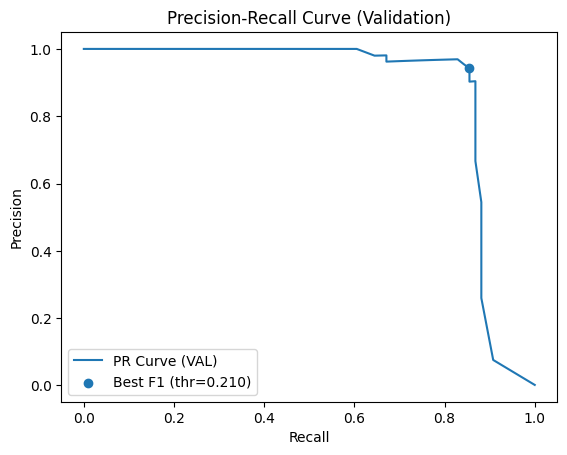

In [ ]:
# -------------------------
# 8) THRESHOLD SELECTION (VALIDATION SET) -
# Tujuan: pilih threshold terbaik di validation (bukan default 0.5)
# Kriteria utama: maximize F1 (bisa kamu ganti jadi maximize MCC/Recall kalau mau)
# -------------------------

# 1) Predicted probability (fraud=1) pada validation set
val_proba = best_model.predict_proba(X_val)[:, 1]

# 2) PR curve points
prec, rec, thr = precision_recall_curve(y_val, val_proba)

# 3) Hitung F1 untuk tiap titik PR (hindari div 0)
f1_scores = (2 * prec * rec) / (prec + rec + 1e-12)

# NOTE penting:
# len(prec) == len(rec) == len(thr)+1
# jadi threshold yang sesuai biasanya thr[i-1] untuk titik PR i
best_idx = int(np.argmax(f1_scores))

if best_idx == 0:
    best_thr = 0.5
else:
    thr_idx = best_idx - 1
    best_thr = float(thr[thr_idx]) if 0 <= thr_idx < len(thr) else 0.5

# 4) Metrik validation (pakai probabilitas)
val_roc = roc_auc_score(y_val, val_proba)
val_ap  = average_precision_score(y_val, val_proba)

# 5) Metrik validation (pakai threshold terbaik)
val_pred_opt = (val_proba >= best_thr).astype(int)
val_prec = precision_score(y_val, val_pred_opt, zero_division=0)
val_rec  = recall_score(y_val, val_pred_opt, zero_division=0)
val_f1   = f1_score(y_val, val_pred_opt, zero_division=0)
val_bacc = balanced_accuracy_score(y_val, val_pred_opt)
val_mcc  = matthews_corrcoef(y_val, val_pred_opt)

print("\n=== STEP 8: THRESHOLD SELECTION (VALIDATION) ===")
print("Optimal Threshold (VAL):", best_thr)
print(f"VAL ROC-AUC: {val_roc:.6f}")
print(f"VAL PR-AUC (AP): {val_ap:.6f}")
print(f"VAL Precision: {val_prec:.6f}")
print(f"VAL Recall: {val_rec:.6f}")
print(f"VAL F1: {val_f1:.6f}")
print(f"VAL Balanced Acc: {val_bacc:.6f}")
print(f"VAL MCC: {val_mcc:.6f}")

# 6) Tabel ringkas threshold: bandingkan 0.5 vs optimal (VAL)
def _eval_threshold(y_true, y_proba, t):
    y_pred = (y_proba >= t).astype(int)
    return {
        "threshold": float(t),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred)
    }

val_cmp = pd.DataFrame([
    _eval_threshold(y_val, val_proba, 0.5),
    _eval_threshold(y_val, val_proba, best_thr)
])
print("\n--- Threshold Comparison (VALIDATION) ---")
val_cmp

# 7) Plot PR Curve + titik best F1
plt.figure()
plt.plot(rec, prec, label="PR Curve (VAL)")
plt.scatter(rec[best_idx], prec[best_idx], marker="o",
            label=f"Best F1 (thr={best_thr:.3f})")
plt.title("Precision-Recall Curve (Validation)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()

# (Opsional) simpan threshold utk dipakai step 9
# best_thr sudah siap dipakai



=== STEP 9: FINAL TEST RESULTS (Optimal Threshold) ===
Threshold used (from VAL): 0.210
TEST ROC-AUC: 0.924760
TEST PR-AUC (AP): 0.800229
TEST Precision: 0.948052
TEST Recall: 0.768421
TEST F1: 0.848837
TEST Balanced Acc: 0.884175
TEST MCC: 0.853310

Classification Report (TEST):
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56651
           1     0.9481    0.7684    0.8488        95

    accuracy                         0.9995     56746
   macro avg     0.9738    0.8842    0.9243     56746
weighted avg     0.9995    0.9995    0.9995     56746

Confusion Matrix (TEST):
 [[56647     4]
 [   22    73]]


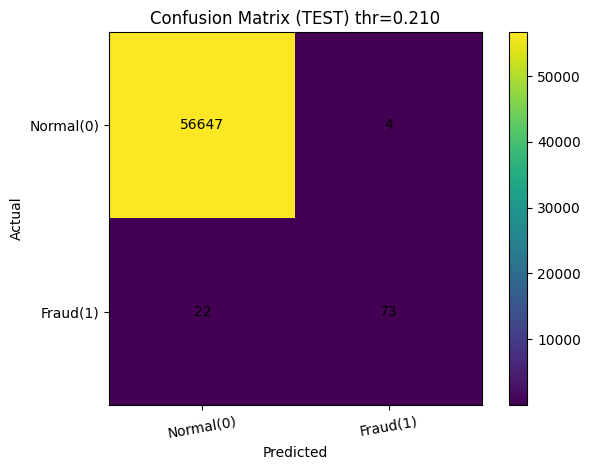

,Threshold,ROC_AUC,PR_AUC_AP,Precision,Recall,F1,Balanced_Accuracy,MCC
0,0.21,0.92476,0.800229,0.948052,0.768421,0.848837,0.884175,0.85331


In [ ]:
# -------------------------
# 9) FINAL EVALUATION (TEST SET) - JOURNAL READY
# - gunakan threshold optimal dari VALIDATION (best_thr)
# - laporkan ROC-AUC, PR-AUC, Precision, Recall, F1, BAcc, MCC + Confusion Matrix
# -------------------------

# Probabilitas fraud pada TEST
test_proba = best_model.predict_proba(X_test)[:, 1]

# Prediksi dengan threshold optimal
test_pred = (test_proba >= best_thr).astype(int)

# Metric berbasis probabilitas
test_roc = roc_auc_score(y_test, test_proba)
test_ap  = average_precision_score(y_test, test_proba)

# Metric berbasis threshold
test_prec = precision_score(y_test, test_pred, zero_division=0)
test_rec  = recall_score(y_test, test_pred, zero_division=0)
test_f1   = f1_score(y_test, test_pred, zero_division=0)
test_bacc = balanced_accuracy_score(y_test, test_pred)
test_mcc  = matthews_corrcoef(y_test, test_pred)

print("\n=== STEP 9: FINAL TEST RESULTS (Optimal Threshold) ===")
print(f"Threshold used (from VAL): {best_thr:.3f}")
print(f"TEST ROC-AUC: {test_roc:.6f}")
print(f"TEST PR-AUC (AP): {test_ap:.6f}")
print(f"TEST Precision: {test_prec:.6f}")
print(f"TEST Recall: {test_rec:.6f}")
print(f"TEST F1: {test_f1:.6f}")
print(f"TEST Balanced Acc: {test_bacc:.6f}")
print(f"TEST MCC: {test_mcc:.6f}")

print("\nClassification Report (TEST):")
print(classification_report(y_test, test_pred, digits=4))

# Confusion matrix
cm = confusion_matrix(y_test, test_pred)
print("Confusion Matrix (TEST):\n", cm)

# Plot confusion matrix (simple & jurnal-friendly)
plt.figure()
plt.imshow(cm)
plt.title(f"Confusion Matrix (TEST) thr={best_thr:.3f}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0,1], ["Normal(0)","Fraud(1)"], rotation=10)
plt.yticks([0,1], ["Normal(0)","Fraud(1)"])
for (i, j), v in np.ndenumerate(cm):
    plt.text(j, i, int(v), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

# Simpan ringkasan metrik test untuk dipakai step berikutnya (tabel jurnal)
test_summary = pd.DataFrame([{
    "Threshold": float(best_thr),
    "ROC_AUC": test_roc,
    "PR_AUC_AP": test_ap,
    "Precision": test_prec,
    "Recall": test_rec,
    "F1": test_f1,
    "Balanced_Accuracy": test_bacc,
    "MCC": test_mcc
}])
test_summary


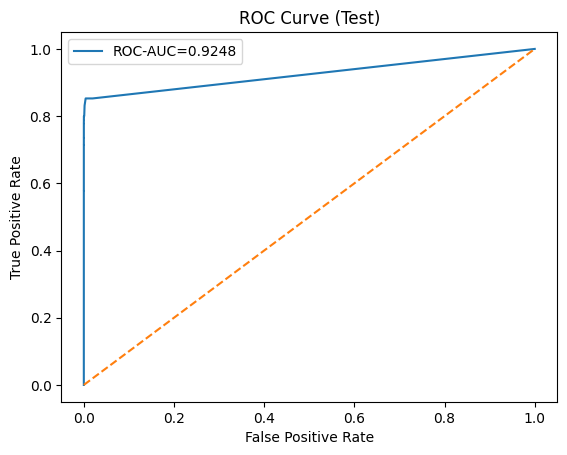

In [ ]:
# -------------------------
# 10) ROC CURVE (TEST)
# -------------------------
fpr, tpr, _ = roc_curve(y_test, test_proba)

plt.figure()
plt.plot(fpr, tpr, label=f"ROC-AUC={test_roc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve (Test)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()


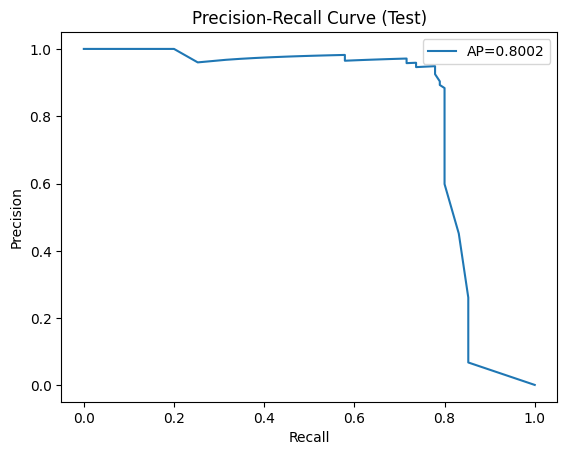

In [ ]:
# -------------------------
# 11) PR CURVE (TEST)
# -------------------------
prec_t, rec_t, _ = precision_recall_curve(y_test, test_proba)

plt.figure()
plt.plot(rec_t, prec_t, label=f"AP={test_ap:.4f}")
plt.title("Precision-Recall Curve (Test)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.show()


In [ ]:
# -------------------------
# 12) FEATURE IMPORTANCE (TOP FEATURES)
# -------------------------

# Ambil nama fitur sesuai pipeline
feature_names = scale_cols + pass_cols

# Ambil feature importance dari Random Forest
importances = best_model.named_steps["rf"].feature_importances_

# Buat dataframe
fi = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

# Tampilkan Top 15
top15_fi = fi.head(15)
top15_fi


,Feature,Importance
15,V14,0.217570
13,V12,0.156155
5,V4,0.099129
11,V10,0.086387
18,V17,0.085052
12,V11,0.052829
4,V3,0.050266
8,V7,0.028263
3,V2,0.022938
17,V16,0.022784


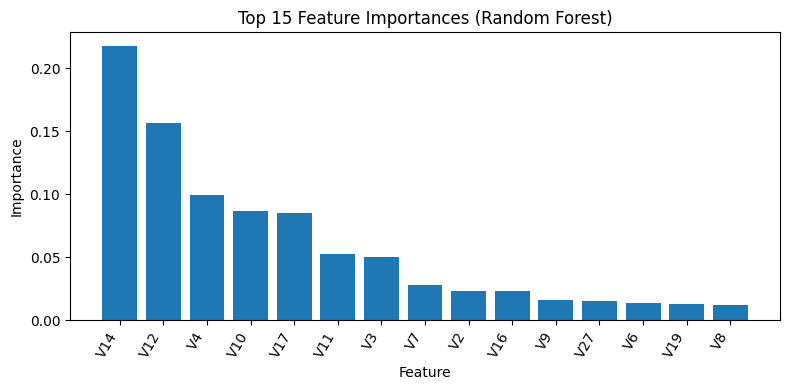

In [ ]:
plt.figure(figsize=(8,4))
plt.bar(top15_fi["Feature"], top15_fi["Importance"])
plt.title("Top 15 Feature Importances (Random Forest)")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# -------------------------
# 13) SAVE ARTIFACTS (MODEL, METRICS, CONFIG)
# -------------------------
import os, json

os.makedirs("artifacts", exist_ok=True)

# Simpan model
joblib.dump(best_model, "artifacts/random_forest_fraud_model.joblib")

# Simpan summary metrik TEST (dari Step 9)
test_summary.to_csv("artifacts/test_summary_metrics.csv", index=False)

# Simpan perbandingan threshold (kalau ada)
try:
    threshold_comparison.to_csv("artifacts/threshold_comparison.csv", index=False)
except:
    pass

# Simpan feature importance
fi.to_csv("artifacts/feature_importances.csv", index=False)

# Simpan konfigurasi eksperimen
experiment_config = {
    "random_state": RANDOM_STATE,
    "dataset": "Kaggle Credit Card Fraud Detection",
    "split": {
        "train": 0.64,
        "validation": 0.16,
        "test": 0.20
    },
    "preprocessing": "StandardScaler(Time, Amount), passthrough V1-V28",
    "model": "RandomForestClassifier(class_weight='balanced')",
    "hyperparameter_tuning": {
        "method": "RandomizedSearchCV",
        "cv": "StratifiedKFold",
        "scoring": "average_precision"
    },
    "optimal_threshold": float(best_thr)
}

with open("artifacts/experiment_config.json", "w") as f:
    json.dump(experiment_config, f, indent=2)

print("\nArtifacts berhasil disimpan di folder /content/artifacts")



Artifacts berhasil disimpan di folder /content/artifacts


In [ ]:
# -------------------------
# ENVIRONMENT INFO (for reproducibility)
# -------------------------
import sys, sklearn

env_info = {
    "Python": sys.version,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "Scikit-learn": sklearn.__version__
}

env_info


{'Python': '3.12.12 (main, Oct 10 2025, 08:52:57) [GCC 11.4.0]',
 'NumPy': '2.0.2',
 'Pandas': '2.2.2',
 'Scikit-learn': '1.6.1'}